# Higgs Boson Classification — End-to-End ML Project

Complete workflow: EDA, missing-value handling, outlier analysis, leakage-safe Scikit-learn Pipelines, multiple classification families, cross-validation, Optuna tuning, ensemble learning, evaluation, and test predictions.

**Target:** `s` = Signal (1), `b` = Background (0).  
**Expected files:** `data/training.csv` and `data/test.csv`.

Important:
- `-999` is treated as a missing-value marker.
- `Weight` and `EventId`, if present, are excluded from model features.
- All learned preprocessing is fitted inside each Pipeline.
- The official test file is not used for model selection.
- Large/slow models use configurable stratified samples to keep runtime manageable.

## 0. Install packages
Run once if needed, then restart the kernel.

In [1]:
%pip install -U numpy pandas matplotlib seaborn scipy scikit-learn optuna joblib
%pip install -U xgboost lightgbm catboost plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 1. Imports and configuration

In [2]:
import os, time, warnings, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import optuna
import joblib

from sklearn.preprocessing import FunctionTransformer, StandardScaler, RobustScaler, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression, SGDClassifier, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier,
    VotingClassifier, StackingClassifier
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
RANDOM_STATE = 42
TARGET = "Label"
DATA_DIR = Path("data")
TRAIN_PATH = DATA_DIR / "training.csv"
TEST_PATH = DATA_DIR / "test.csv"

VALIDATION_SIZE = 0.20
CV_SPLITS = 3
BASELINE_SAMPLE_LIMIT = 100_000
TUNING_SAMPLE_LIMIT = 60_000
SVC_SAMPLE_LIMIT = 12_000
KNN_SAMPLE_LIMIT = 30_000
N_TRIALS = 15

sns.set_theme(style="whitegrid")

c:\Users\hamas\OneDrive\Desktop\Data_Analysis\Projects\Higgs_Boson_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load CSV files
This cell explicitly detects missing files and empty CSVs.

In [3]:
def read_csv_checked(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path.resolve()}. Check the data/ folder.")
    if path.stat().st_size == 0:
        raise ValueError(f"{path} is empty (0 bytes). Re-download the original CSV.")
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError as exc:
        raise ValueError(f"{path} has no readable CSV columns.") from exc

train_df = read_csv_checked(TRAIN_PATH)
test_df = read_csv_checked(TEST_PATH)
print("Training:", train_df.shape, "| Test:", test_df.shape)
print(train_df.columns.tolist())
display(train_df.head())

Training: (250000, 33) | Test: (550000, 31)
['EventId', 'DER_mass_MMC', 'DER_mass_transverse_met_lep', 'DER_mass_vis', 'DER_pt_h', 'DER_deltaeta_jet_jet', 'DER_mass_jet_jet', 'DER_prodeta_jet_jet', 'DER_deltar_tau_lep', 'DER_pt_tot', 'DER_sum_pt', 'DER_pt_ratio_lep_tau', 'DER_met_phi_centrality', 'DER_lep_eta_centrality', 'PRI_tau_pt', 'PRI_tau_eta', 'PRI_tau_phi', 'PRI_lep_pt', 'PRI_lep_eta', 'PRI_lep_phi', 'PRI_met', 'PRI_met_phi', 'PRI_met_sumet', 'PRI_jet_num', 'PRI_jet_leading_pt', 'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_pt', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi', 'PRI_jet_all_pt', 'Weight', 'Label']


,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,...,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label
0,100000,138.470,51.655,97.827,27.980,0.91,124.711,2.666,3.064,41.928,...,2,67.435,2.150,0.444,46.062,1.24,-2.475,113.497,0.002653,s
1,100001,160.937,68.768,103.235,48.146,-999.00,-999.000,-999.000,3.473,2.078,...,1,46.226,0.725,1.158,-999.000,-999.00,-999.000,46.226,2.233584,b
2,100002,-999.000,162.172,125.953,35.635,-999.00,-999.000,-999.000,3.148,9.336,...,1,44.251,2.053,-2.028,-999.000,-999.00,-999.000,44.251,2.347389,b
3,100003,143.905,81.417,80.943,0.414,-999.00,-999.000,-999.000,3.310,0.414,...,0,-999.000,-999.000,-999.000,-999.000,-999.00,-999.000,-0.000,5.446378,b
4,100004,175.864,16.915,134.805,16.405,-999.00,-999.000,-999.000,3.891,16.405,...,0,-999.000,-999.000,-999.000,-999.000,-999.00,-999.000,0.000,6.245333,b


## 3. Separate target, metadata, and features

In [4]:
if TARGET not in train_df.columns:
    raise ValueError(f"'{TARGET}' not found. Columns: {train_df.columns.tolist()}")

event_weights = pd.to_numeric(train_df["Weight"], errors="coerce") if "Weight" in train_df else None
excluded = [c for c in [TARGET, "Weight", "EventId"] if c in train_df.columns]
feature_columns = [c for c in train_df.columns if c not in excluded and c in test_df.columns]
if not feature_columns:
    raise ValueError("No common feature columns between train and test.")

X = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()
labels = train_df[TARGET].astype(str).str.strip().str.lower()
y = labels.map({"b": 0, "s": 1})
if y.isna().any():
    raise ValueError(f"Unexpected target labels: {labels[y.isna()].unique().tolist()}")
y = y.astype("int8")

print("Features:", len(feature_columns))
print("Excluded metadata:", excluded)
display(y.value_counts().rename(index={0:"Background (b)",1:"Signal (s)"}).to_frame("count"))
display((y.value_counts(normalize=True)*100).rename(index={0:"Background (b)",1:"Signal (s)"}).round(2).to_frame("percentage"))

Features: 30
Excluded metadata: ['Label', 'Weight', 'EventId']


,count
Label,
Background (b),164333
Signal (s),85667


,percentage
Label,
Background (b),65.73
Signal (s),34.27


## 4. Data quality and missing values

,missing_count,missing_percentage
DER_deltaeta_jet_jet,177457,70.9828
DER_mass_jet_jet,177457,70.9828
DER_lep_eta_centrality,177457,70.9828
DER_prodeta_jet_jet,177457,70.9828
PRI_jet_subleading_pt,177457,70.9828
PRI_jet_subleading_phi,177457,70.9828
PRI_jet_subleading_eta,177457,70.9828
PRI_jet_leading_pt,99913,39.9652
PRI_jet_leading_eta,99913,39.9652
PRI_jet_leading_phi,99913,39.9652


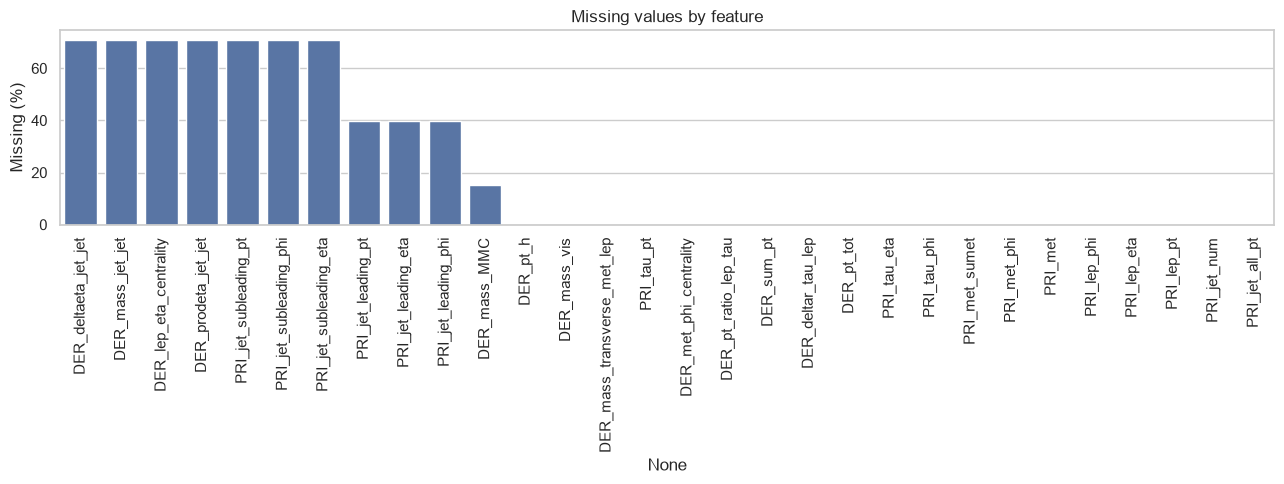

Duplicate rows: 0
Data types:


float64    29
int64       1
Name: count, dtype: int64

In [5]:
X_eda = X.replace(-999, np.nan)
missing = pd.DataFrame({
    "missing_count": X_eda.isna().sum(),
    "missing_percentage": X_eda.isna().mean()*100
}).sort_values("missing_percentage", ascending=False)
display(missing)
plt.figure(figsize=(13,5))
sns.barplot(x=missing.index, y=missing["missing_percentage"])
plt.xticks(rotation=90)
plt.ylabel("Missing (%)")
plt.title("Missing values by feature")
plt.tight_layout()
plt.show()

print("Duplicate rows:", X.duplicated().sum())
print("Data types:")
display(X.dtypes.value_counts())

## 5. Feature distributions

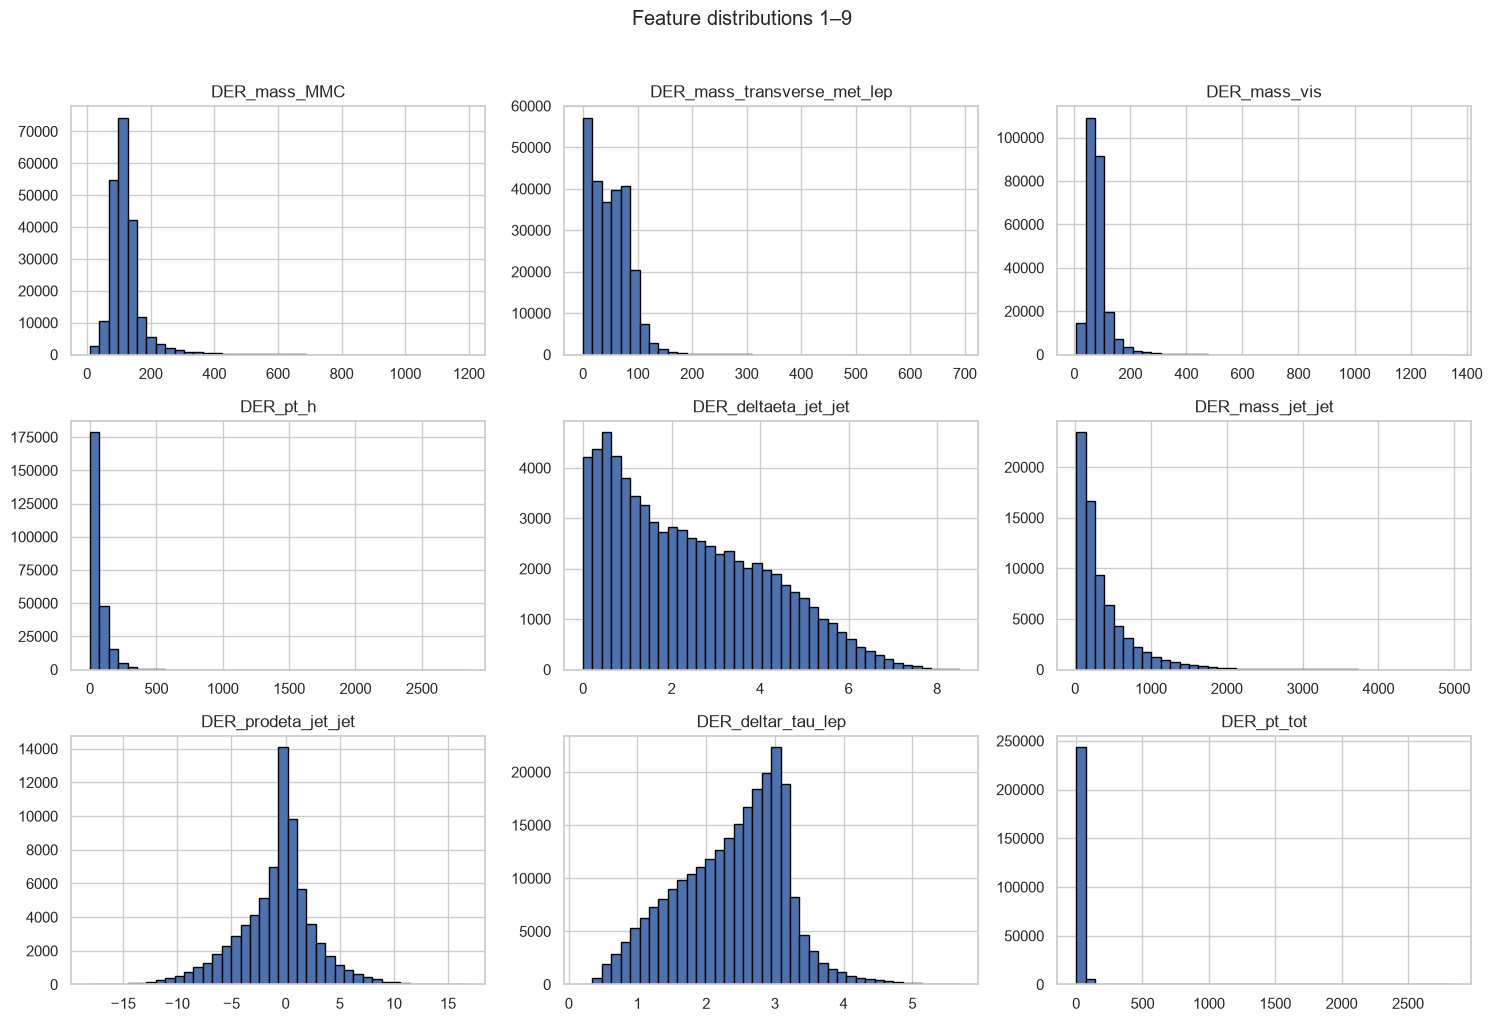

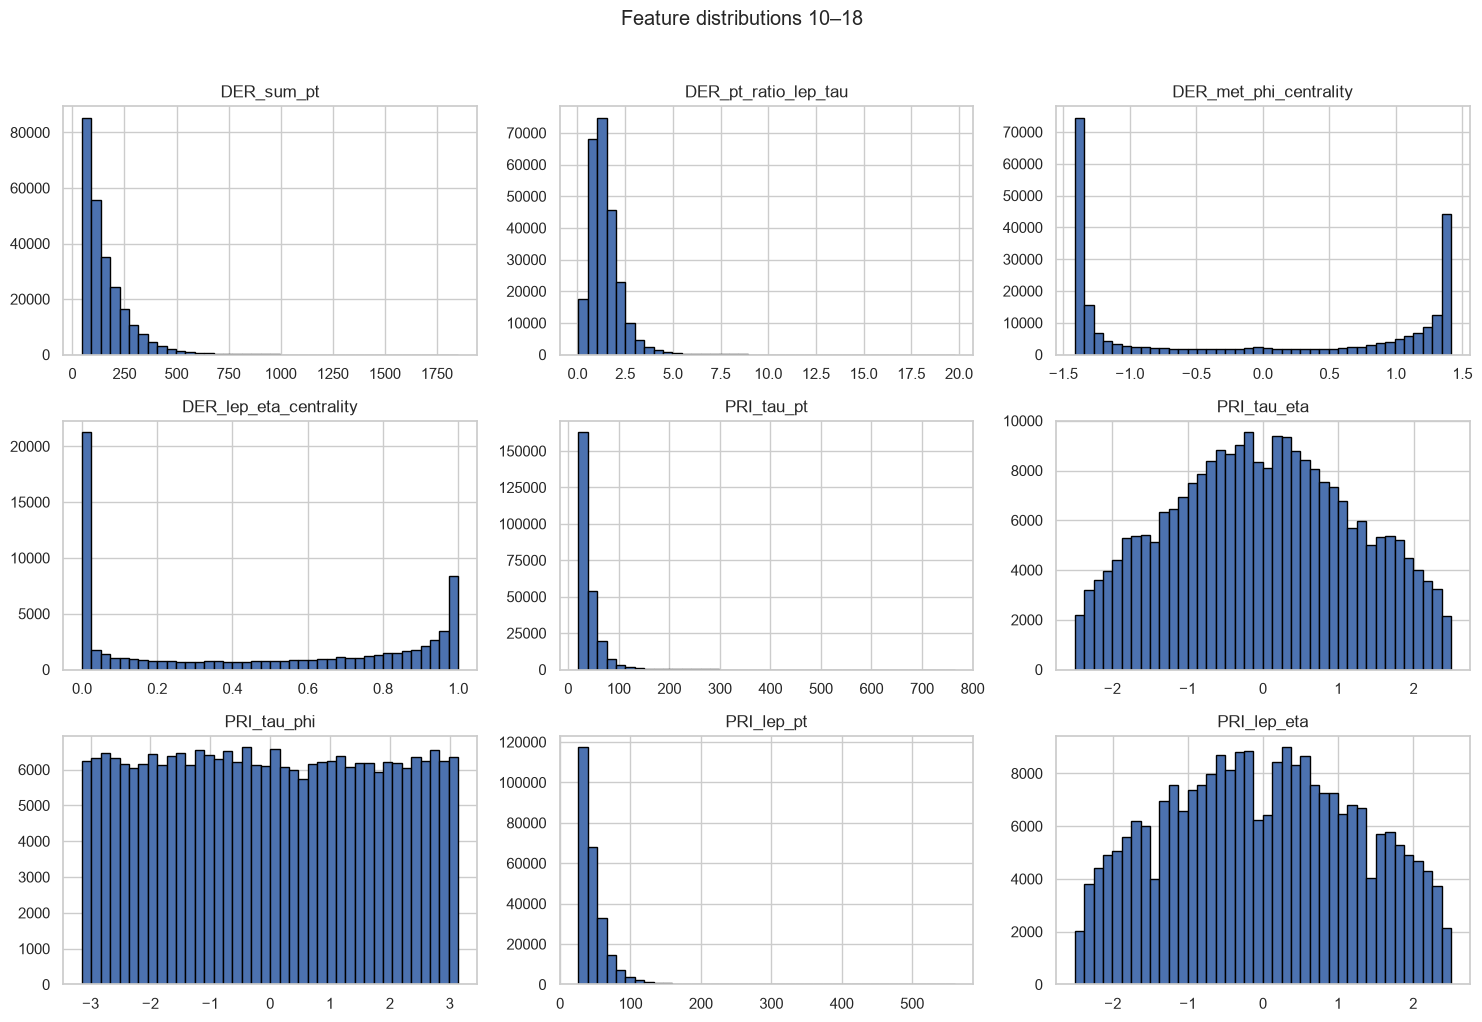

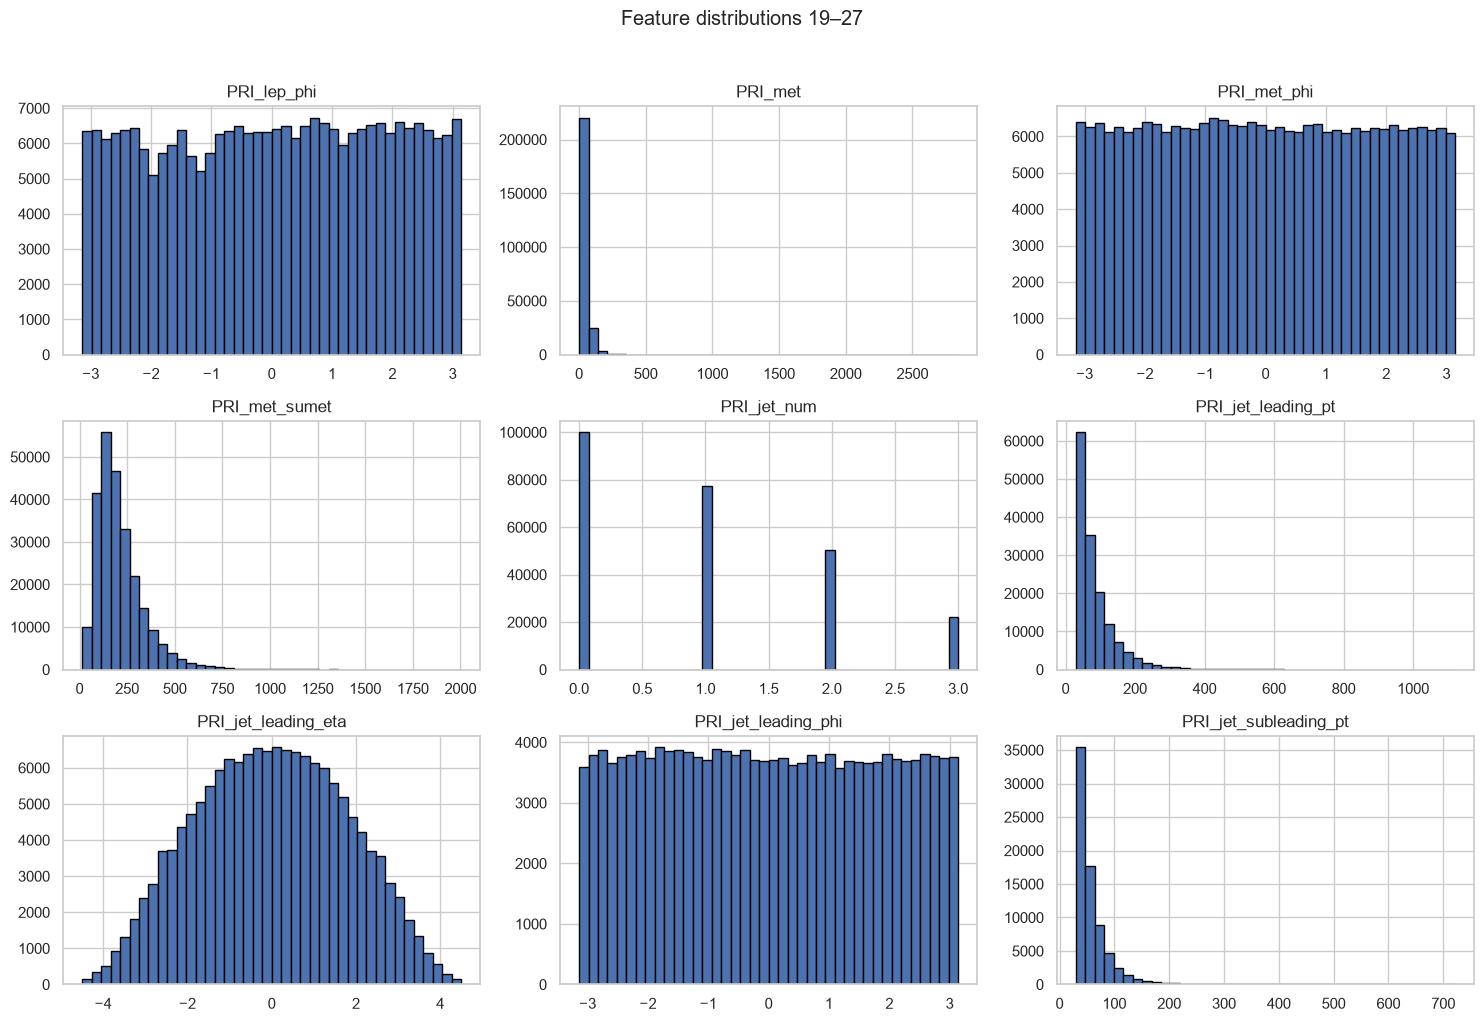

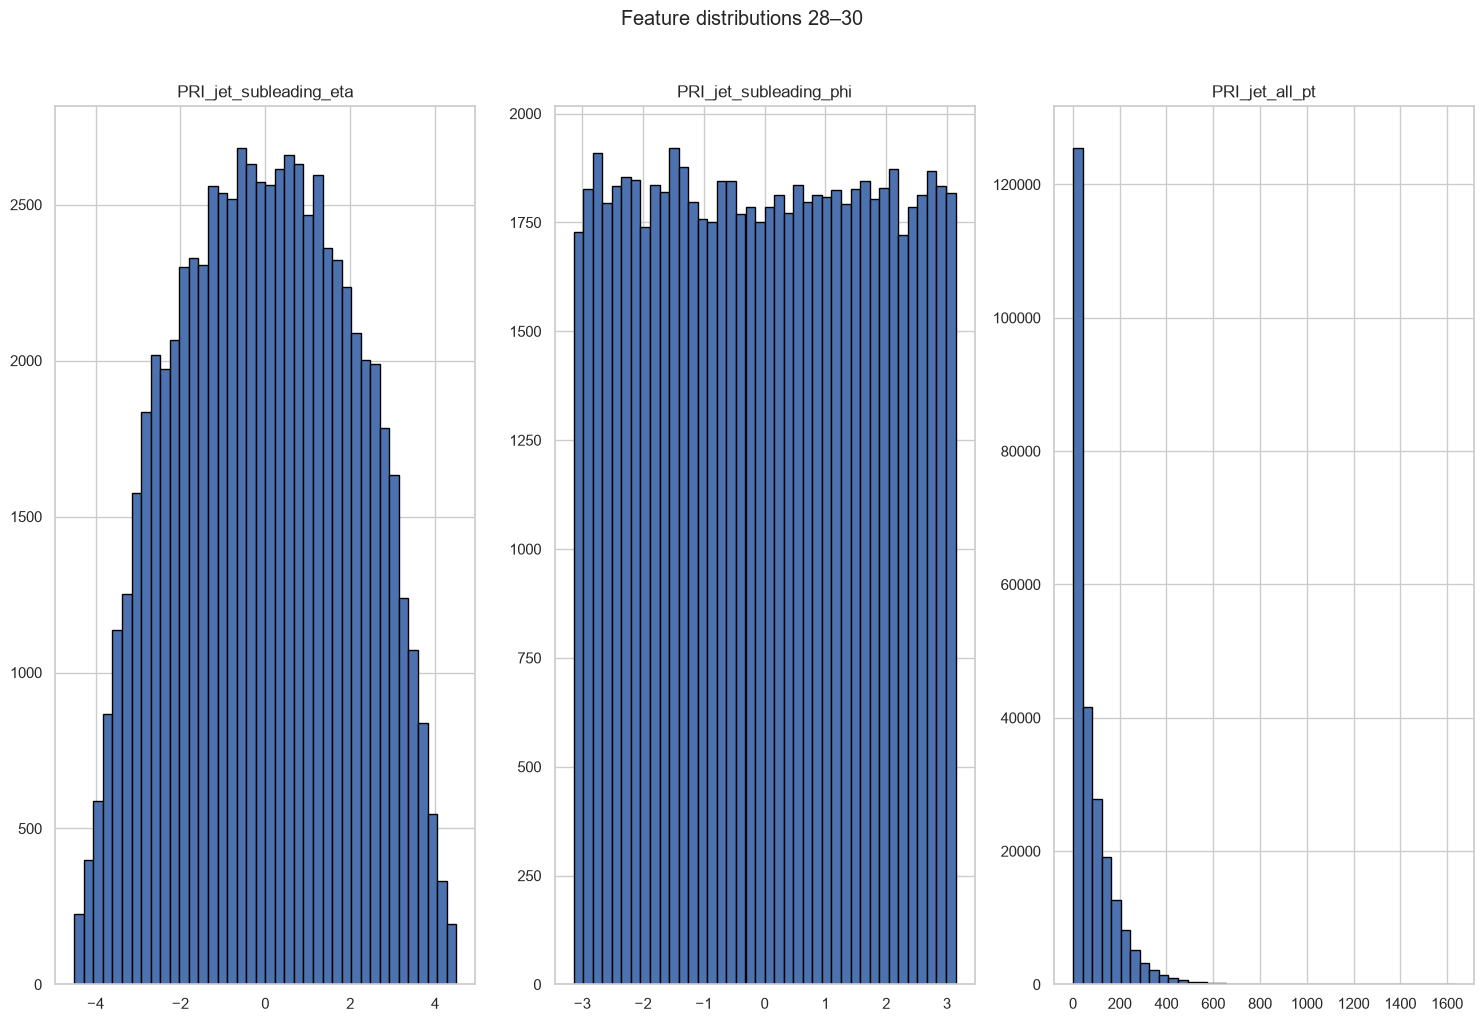

In [6]:
numeric_features = X_eda.select_dtypes(include=np.number).columns.tolist()
for start in range(0, len(numeric_features), 9):
    cols = numeric_features[start:start+9]
    X_eda[cols].hist(figsize=(15,10), bins=40, layout=(-1,3), edgecolor="black")
    plt.suptitle(f"Feature distributions {start+1}–{start+len(cols)}", y=1.02)
    plt.tight_layout()
    plt.show()

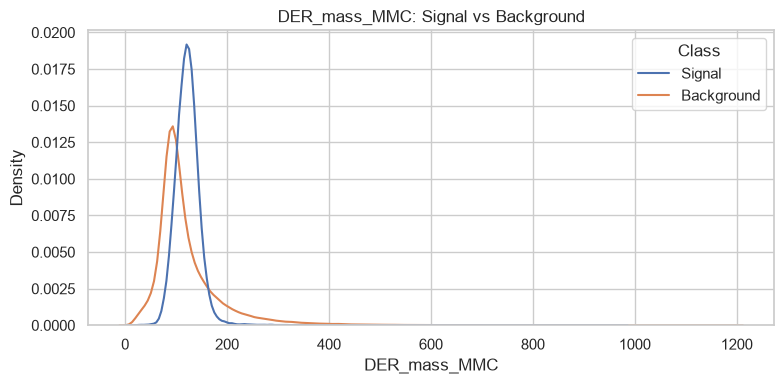

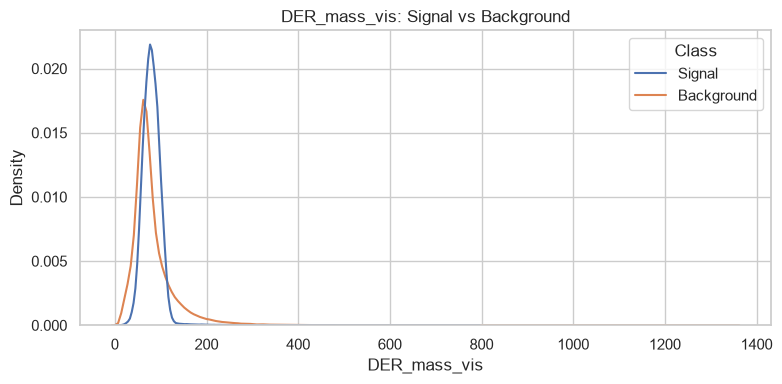

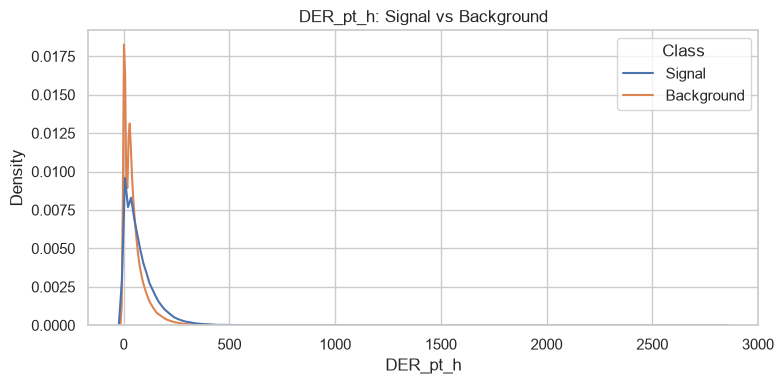

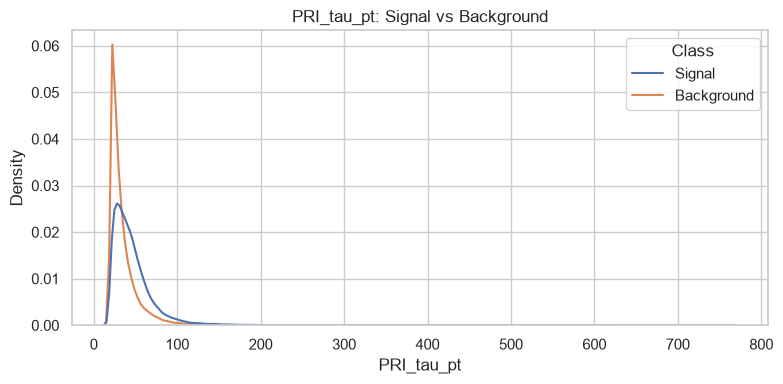

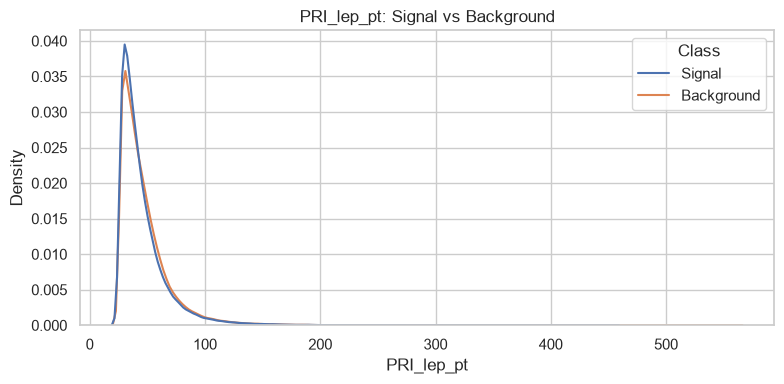

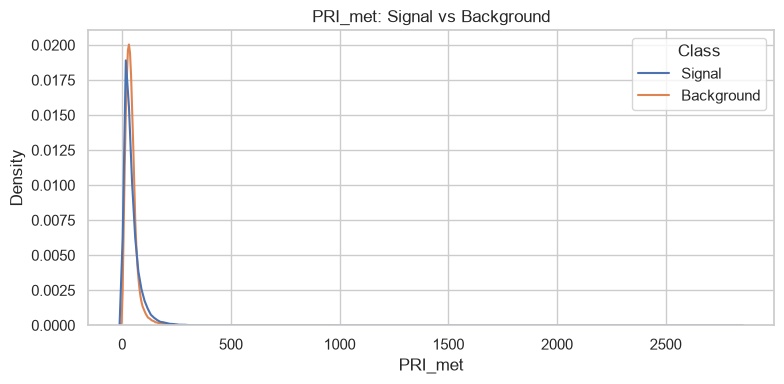

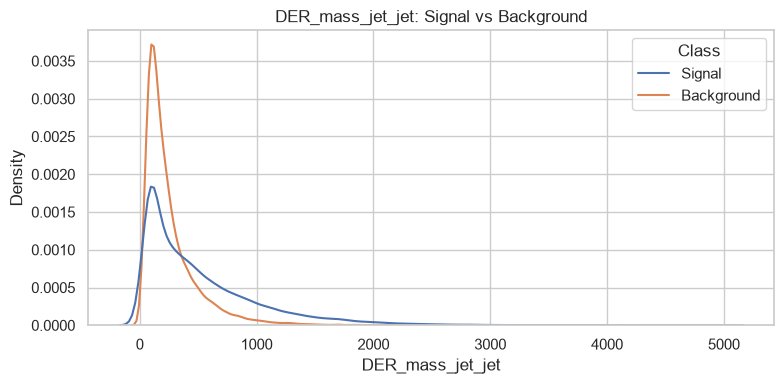

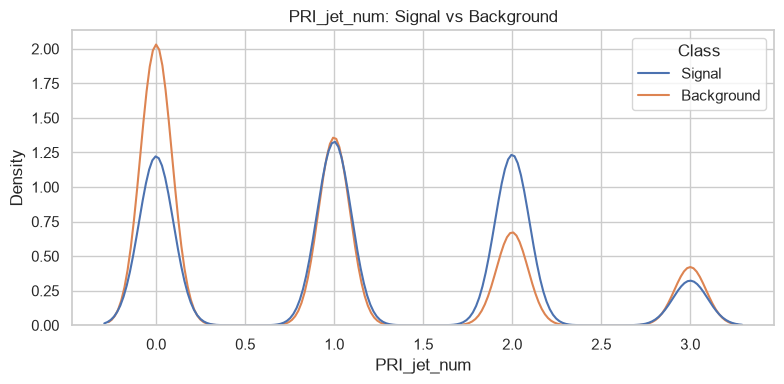

In [7]:
selected = [c for c in [
    "DER_mass_MMC","DER_mass_vis","DER_pt_h","PRI_tau_pt",
    "PRI_lep_pt","PRI_met","DER_mass_jet_jet","PRI_jet_num"
] if c in X_eda.columns]
for col in selected:
    temp = pd.DataFrame({col:X_eda[col], "Class":y.map({0:"Background",1:"Signal"})}).dropna()
    plt.figure(figsize=(8,4))
    sns.kdeplot(data=temp, x=col, hue="Class", common_norm=False)
    plt.title(f"{col}: Signal vs Background")
    plt.tight_layout()
    plt.show()

## 6. Outlier inspection (IQR)
Outliers are flagged for investigation, not automatically removed. Rare high-energy events may be physically valid.

In [8]:
outlier_rows = []
for col in numeric_features:
    s = X_eda[col].dropna()
    if s.empty: 
        continue
    q1, q3 = s.quantile([0.25,0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    count = ((s<lo)|(s>hi)).sum()
    outlier_rows.append({
        "Feature":col, "Lower_Bound":lo, "Upper_Bound":hi,
        "Outlier_Count":int(count), "Outlier_Percentage":100*count/len(s),
        "Skewness":s.skew(), "Min":s.min(), "Max":s.max()
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values("Outlier_Percentage",ascending=False)
display(outlier_summary)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage,Skewness,Min,Max
5,DER_mass_jet_jet,-437.396500,1027.599500,5127,7.067532,2.457852,13.602,4974.979
6,DER_prodeta_jet_jet,-8.009500,6.338500,4641,6.397585,-0.328458,-18.066,16.690
0,DER_mass_MMC,26.490125,200.877125,13464,6.354360,3.807351,9.044,1192.026
23,PRI_jet_leading_pt,-43.956750,191.721250,8892,5.924564,2.564700,30.000,1120.573
26,PRI_jet_subleading_pt,-6.675500,110.624500,4296,5.922005,3.394232,30.000,721.456
2,DER_mass_vis,10.083375,141.564375,14611,5.844400,3.790262,6.329,1349.351
13,PRI_tau_pt,-6.046125,75.654875,13925,5.570000,3.755191,20.000,764.408
3,DER_pt_h,-83.581625,176.819375,13891,5.556400,2.541885,0.000,2834.999
16,PRI_lep_pt,0.852500,84.912500,13434,5.373600,3.240762,26.000,560.271
19,PRI_met,-24.347500,97.640500,13299,5.319600,5.270755,0.109,2842.617


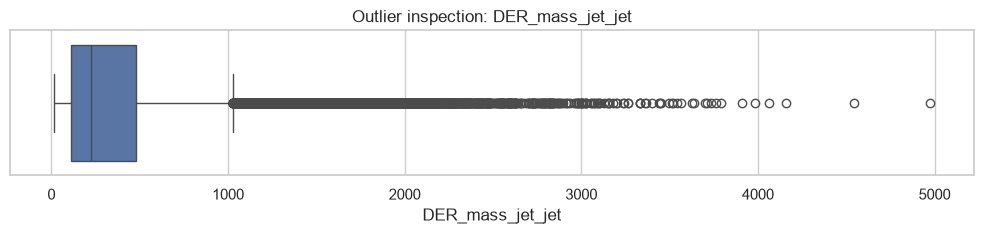

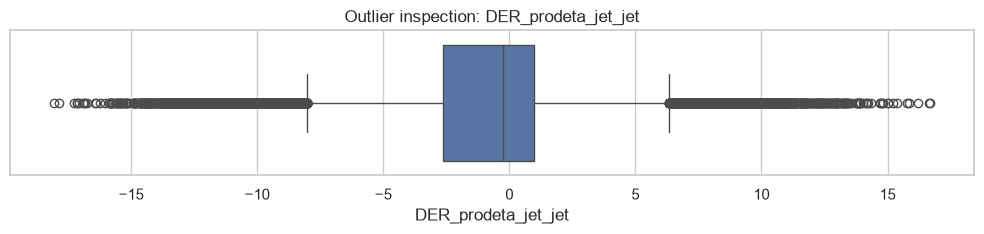

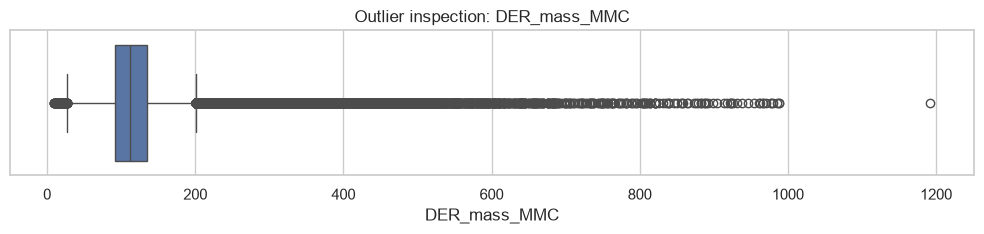

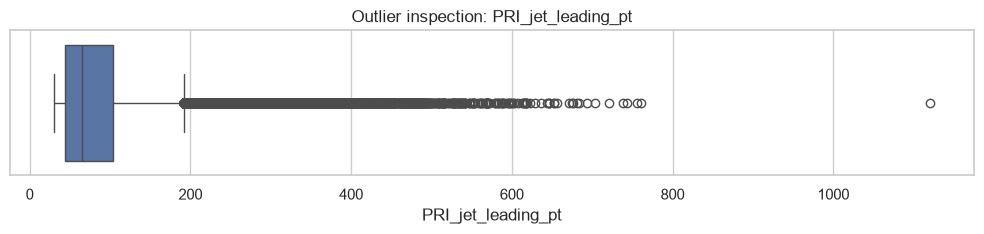

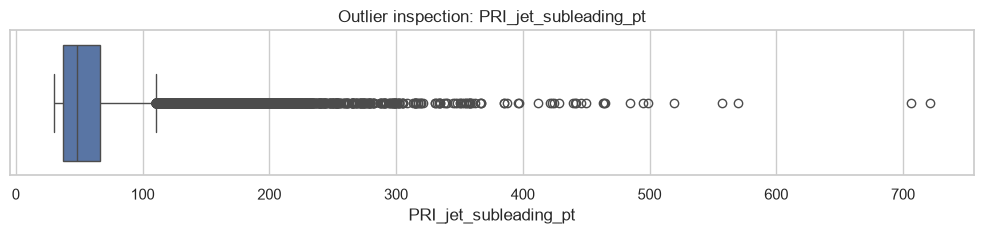

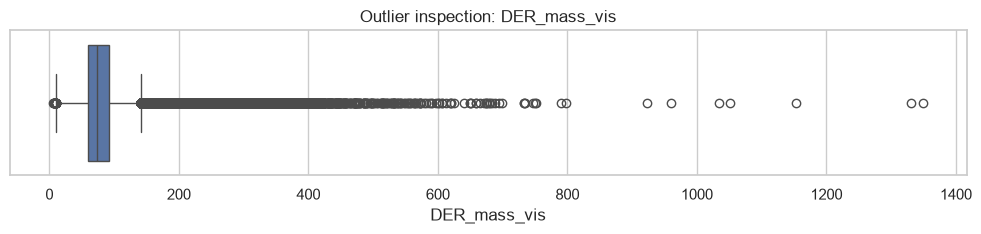

In [9]:
top_outlier_features = outlier_summary.head(6)["Feature"].tolist()
for col in top_outlier_features:
    plt.figure(figsize=(10,2.5))
    sns.boxplot(x=X_eda[col])
    plt.title(f"Outlier inspection: {col}")
    plt.tight_layout()
    plt.show()

## 7. Train/validation split
Split first. Preprocessing will be learned only inside each training fold.

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=VALIDATION_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_valid.shape)

(200000, 30) (50000, 30)


## 8. Reusable leakage-safe Pipeline factory
The sentinel converter changes `-999` to NaN. The imputer and scaler are fitted inside cross-validation folds.

In [11]:
def sentinel_to_nan(X):
    if isinstance(X, pd.DataFrame):
        return X.replace(-999, np.nan)
    arr = np.asarray(X, dtype=float).copy()
    arr[arr == -999] = np.nan
    return arr

def make_preprocessor(scale=None, power=False):
    steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if power:
        steps.append(("power", PowerTransformer(method="yeo-johnson", standardize=False)))
    if scale == "standard":
        steps.append(("scaler", StandardScaler()))
    elif scale == "robust":
        steps.append(("scaler", RobustScaler()))
    return Pipeline(steps)

def make_pipeline(model, scale=None, power=False):
    return Pipeline([
        ("missing_sentinel", FunctionTransformer(sentinel_to_nan, feature_names_out="one-to-one")),
        ("preprocess", make_preprocessor(scale=scale, power=power)),
        ("classifier", model)
    ])

def stratified_sample(Xd, yd, limit):
    if limit is None or len(Xd) <= limit:
        return Xd, yd
    return train_test_split(
        Xd, yd, train_size=limit, stratify=yd, random_state=RANDOM_STATE
    )[0::2]  # returns X_sample, y_sample

## 9. Baseline model zoo
Includes linear, distance-based, SVM, Naive Bayes, tree, bagging, and boosting models. Optional libraries are included if installed.

In [12]:
model_specs = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), "standard"),
    "SGD Classifier": (SGDClassifier(loss="log_loss", max_iter=2000, random_state=RANDOM_STATE), "standard"),
    "Ridge Classifier": (RidgeClassifier(), "standard"),
    "KNN": (KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1), "standard"),
    "SVC RBF": (SVC(C=1, kernel="rbf", probability=True, random_state=RANDOM_STATE), "standard"),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"), None),
    "Random Forest (Bagging)": (RandomForestClassifier(n_estimators=250, n_jobs=-1, class_weight="balanced_subsample", random_state=RANDOM_STATE), None),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=250, n_jobs=-1, class_weight="balanced", random_state=RANDOM_STATE), None),
    "Bagging Tree": (BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=12), n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE), None),
    "AdaBoost": (AdaBoostClassifier(n_estimators=150, random_state=RANDOM_STATE), None),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), None),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=150, random_state=RANDOM_STATE), None),
    "Gaussian Naive Bayes": (GaussianNB(), "standard")
}

try:
    from xgboost import XGBClassifier
    model_specs["XGBoost"] = (XGBClassifier(n_estimators=250,max_depth=6,learning_rate=.05,subsample=.8,colsample_bytree=.8,eval_metric="logloss",random_state=RANDOM_STATE,n_jobs=-1), None)
except ImportError: print("XGBoost unavailable — skipped")
try:
    from lightgbm import LGBMClassifier
    model_specs["LightGBM"] = (LGBMClassifier(n_estimators=250,learning_rate=.05,verbosity=-1,random_state=RANDOM_STATE,n_jobs=-1), None)
except ImportError: print("LightGBM unavailable — skipped")
try:
    from catboost import CatBoostClassifier
    model_specs["CatBoost"] = (CatBoostClassifier(iterations=250,depth=6,learning_rate=.05,verbose=False,random_seed=RANDOM_STATE,thread_count=-1), None)
except ImportError: print("CatBoost unavailable — skipped")

print("Available models:", list(model_specs))

Available models: ['Logistic Regression', 'SGD Classifier', 'Ridge Classifier', 'KNN', 'SVC RBF', 'Decision Tree', 'Random Forest (Bagging)', 'Extra Trees', 'Bagging Tree', 'AdaBoost', 'Gradient Boosting', 'HistGradientBoosting', 'Gaussian Naive Bayes', 'XGBoost', 'LightGBM', 'CatBoost']


## 10. Baseline cross-validation

In [13]:
def sample_for_model(name, Xd, yd, tuning=False):
    if name == "SVC RBF": limit = SVC_SAMPLE_LIMIT
    elif name == "KNN": limit = KNN_SAMPLE_LIMIT
    else: limit = TUNING_SAMPLE_LIMIT if tuning else BASELINE_SAMPLE_LIMIT
    if len(Xd) <= limit: return Xd, yd
    Xs, _, ys, _ = train_test_split(Xd, yd, train_size=limit, stratify=yd, random_state=RANDOM_STATE)
    return Xs, ys

baseline_rows = []
baseline_pipelines = {}
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

for name, (model, scale) in model_specs.items():
    print("Baseline:", name)
    Xs, ys = sample_for_model(name, X_train, y_train)
    pipe = make_pipeline(model, scale)
    t0 = time.time()
    try:
        scores = cross_val_score(pipe, Xs, ys, cv=cv, scoring="roc_auc", n_jobs=1)
        pipe.fit(Xs, ys)
        baseline_pipelines[name] = pipe
        Xv, yv = sample_for_model(name, X_valid, y_valid)
        pred = pipe.predict(Xv)
        score = pipe.predict_proba(Xv)[:,1] if hasattr(pipe,"predict_proba") else None
        baseline_rows.append({
            "Model":name, "CV_ROC_AUC_Mean":scores.mean(), "CV_ROC_AUC_Std":scores.std(),
            "Validation_Accuracy":accuracy_score(yv,pred),
            "Validation_F1":f1_score(yv,pred,zero_division=0),
            "Validation_ROC_AUC":roc_auc_score(yv,score) if score is not None else np.nan,
            "Time_sec":time.time()-t0, "Rows_Used":len(Xs)
        })
    except Exception as e:
        print("Skipped", name, "because:", repr(e))

baseline_results = pd.DataFrame(baseline_rows).sort_values("CV_ROC_AUC_Mean",ascending=False)
display(baseline_results)

Baseline: Logistic Regression
Baseline: SGD Classifier
Baseline: Ridge Classifier
Baseline: KNN
Baseline: SVC RBF
Baseline: Decision Tree
Baseline: Random Forest (Bagging)
Baseline: Extra Trees
Baseline: Bagging Tree
Baseline: AdaBoost
Baseline: Gradient Boosting
Baseline: HistGradientBoosting
Baseline: Gaussian Naive Bayes
Baseline: XGBoost
Baseline: LightGBM
Baseline: CatBoost


,Model,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,Validation_Accuracy,Validation_F1,Validation_ROC_AUC,Time_sec,Rows_Used
13,XGBoost,0.908441,0.000792,0.839800,0.756387,0.907880,9.618796,100000
14,LightGBM,0.907421,0.000925,0.839620,0.755033,0.906875,6.818067,100000
11,HistGradientBoosting,0.906706,0.000540,0.838760,0.754656,0.906765,12.800703,100000
15,CatBoost,0.905882,0.001121,0.837160,0.749985,0.904873,15.916481,100000
6,Random Forest (Bagging),0.902841,0.001255,0.835920,0.743079,0.902671,56.011343,100000
8,Bagging Tree,0.899151,0.000946,0.832860,0.745159,0.899814,116.337082,100000
10,Gradient Boosting,0.898837,0.000458,0.829900,0.738106,0.897104,216.308789,100000
7,Extra Trees,0.896548,0.001753,0.831080,0.731941,0.895972,31.018008,100000
9,AdaBoost,0.879737,0.001912,0.814020,0.711471,0.879409,143.432075,100000
4,SVC RBF,0.876813,0.002099,0.816000,0.708861,0.884728,59.354707,12000


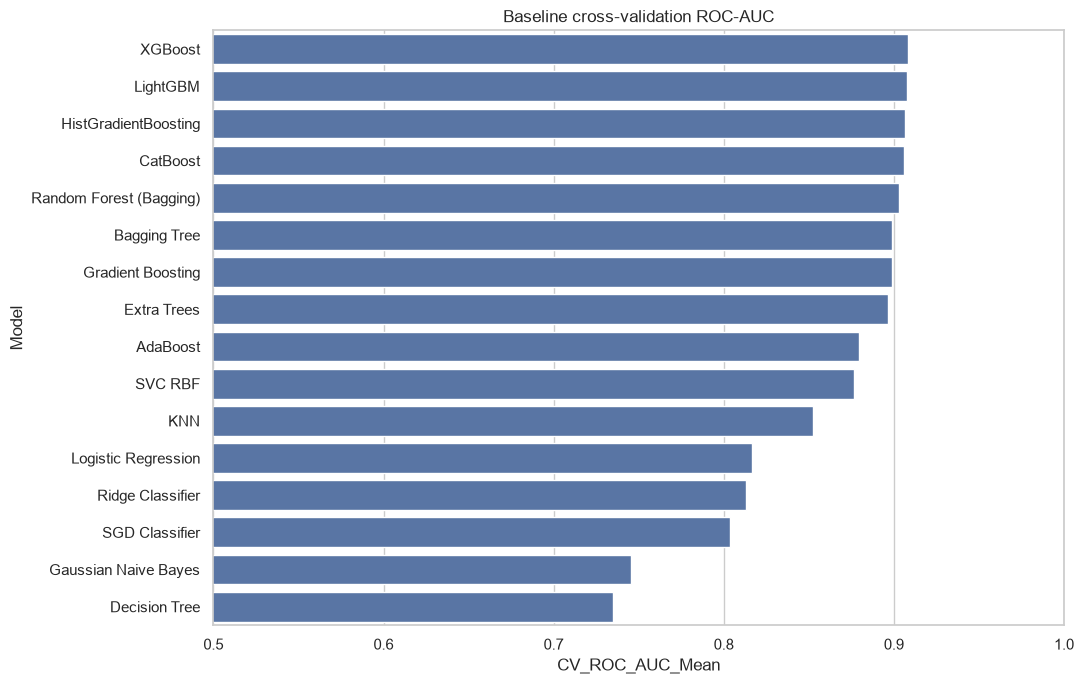

In [14]:
plt.figure(figsize=(11,7))
sns.barplot(data=baseline_results, x="CV_ROC_AUC_Mean", y="Model")
plt.title("Baseline cross-validation ROC-AUC")
plt.xlim(.5,1)
plt.tight_layout()
plt.show()

## 11. Optuna search spaces
Each model receives its own hyperparameter search space. Tuning is performed on training data only.

In [15]:
def suggest_model(trial, name):
    if name == "Logistic Regression":
        m=LogisticRegression(C=trial.suggest_float("C",1e-3,100,log=True),max_iter=2500,random_state=RANDOM_STATE); sc="standard"
    elif name == "SGD Classifier":
        m=SGDClassifier(loss="log_loss",alpha=trial.suggest_float("alpha",1e-6,1e-2,log=True),penalty=trial.suggest_categorical("penalty",["l2","l1","elasticnet"]),max_iter=2500,random_state=RANDOM_STATE); sc="standard"
    elif name == "Ridge Classifier":
        m=RidgeClassifier(alpha=trial.suggest_float("alpha",1e-3,100,log=True)); sc="standard"
    elif name == "KNN":
        m=KNeighborsClassifier(n_neighbors=trial.suggest_int("n_neighbors",5,45,step=2),weights=trial.suggest_categorical("weights",["uniform","distance"]),p=trial.suggest_int("p",1,2),n_jobs=-1); sc="standard"
    elif name == "SVC RBF":
        m=SVC(C=trial.suggest_float("C",.01,30,log=True),gamma=trial.suggest_categorical("gamma",["scale","auto"]),probability=True,random_state=RANDOM_STATE); sc="standard"
    elif name == "Decision Tree":
        m=DecisionTreeClassifier(max_depth=trial.suggest_int("max_depth",3,30),min_samples_split=trial.suggest_int("min_samples_split",2,30),min_samples_leaf=trial.suggest_int("min_samples_leaf",1,20),criterion=trial.suggest_categorical("criterion",["gini","entropy","log_loss"]),class_weight="balanced",random_state=RANDOM_STATE); sc=None
    elif name in ["Random Forest (Bagging)","Extra Trees"]:
        cls=RandomForestClassifier if name.startswith("Random") else ExtraTreesClassifier
        m=cls(n_estimators=trial.suggest_int("n_estimators",150,400,step=50),max_depth=trial.suggest_int("max_depth",5,30),min_samples_leaf=trial.suggest_int("min_samples_leaf",1,10),max_features=trial.suggest_categorical("max_features",["sqrt",.7]),class_weight="balanced",n_jobs=-1,random_state=RANDOM_STATE); sc=None
    elif name == "Bagging Tree":
        base=DecisionTreeClassifier(max_depth=trial.suggest_int("base_max_depth",3,20),min_samples_leaf=trial.suggest_int("min_samples_leaf",1,10),random_state=RANDOM_STATE)
        m=BaggingClassifier(estimator=base,n_estimators=trial.suggest_int("n_estimators",50,200,step=50),max_samples=trial.suggest_float("max_samples",.5,1),n_jobs=-1,random_state=RANDOM_STATE); sc=None
    elif name == "AdaBoost":
        m=AdaBoostClassifier(n_estimators=trial.suggest_int("n_estimators",50,300,step=50),learning_rate=trial.suggest_float("learning_rate",.01,1,log=True),random_state=RANDOM_STATE); sc=None
    elif name == "Gradient Boosting":
        m=GradientBoostingClassifier(n_estimators=trial.suggest_int("n_estimators",80,250,step=30),learning_rate=trial.suggest_float("learning_rate",.01,.2,log=True),max_depth=trial.suggest_int("max_depth",2,5),subsample=trial.suggest_float("subsample",.65,1),random_state=RANDOM_STATE); sc=None
    elif name == "HistGradientBoosting":
        m=HistGradientBoostingClassifier(max_iter=trial.suggest_int("max_iter",100,300,step=50),learning_rate=trial.suggest_float("learning_rate",.02,.2,log=True),max_leaf_nodes=trial.suggest_int("max_leaf_nodes",15,63),l2_regularization=trial.suggest_float("l2_regularization",1e-4,10,log=True),random_state=RANDOM_STATE); sc=None
    elif name == "Gaussian Naive Bayes":
        m=GaussianNB(var_smoothing=trial.suggest_float("var_smoothing",1e-12,1e-6,log=True)); sc="standard"
    elif name == "XGBoost":
        m=XGBClassifier(n_estimators=trial.suggest_int("n_estimators",150,400,step=50),max_depth=trial.suggest_int("max_depth",3,9),learning_rate=trial.suggest_float("learning_rate",.01,.2,log=True),subsample=trial.suggest_float("subsample",.65,1),colsample_bytree=trial.suggest_float("colsample_bytree",.65,1),eval_metric="logloss",random_state=RANDOM_STATE,n_jobs=-1); sc=None
    elif name == "LightGBM":
        m=LGBMClassifier(n_estimators=trial.suggest_int("n_estimators",150,400,step=50),num_leaves=trial.suggest_int("num_leaves",15,63),learning_rate=trial.suggest_float("learning_rate",.01,.2,log=True),verbosity=-1,random_state=RANDOM_STATE,n_jobs=-1); sc=None
    elif name == "CatBoost":
        m=CatBoostClassifier(iterations=trial.suggest_int("iterations",150,400,step=50),depth=trial.suggest_int("depth",4,9),learning_rate=trial.suggest_float("learning_rate",.01,.2,log=True),verbose=False,random_seed=RANDOM_STATE,thread_count=-1); sc=None
    else: raise ValueError("No search space: "+name)
    return m, sc

## 12. Run Optuna for all available models
For a quick test, set `TRIALS_PER_MODEL = 3`. Increase it for more reliable optimization. SVC can be slow even on a sample.

In [16]:
TUNE_MODELS = list(model_specs.keys())
TRIALS_PER_MODEL = N_TRIALS

studies = {}
best_pipelines = {}
tuning_rows = []

for name in TUNE_MODELS:
    print("\nOptimizing:", name)
    Xt, yt = sample_for_model(name, X_train, y_train, tuning=True)

    def objective(trial, model_name=name):
        model, scale = suggest_model(trial, model_name)
        pipe = make_pipeline(model, scale)
        scores = cross_val_score(pipe, Xt, yt, cv=cv, scoring="roc_auc", n_jobs=1)
        return float(scores.mean())

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )
    try:
        study.optimize(objective, n_trials=TRIALS_PER_MODEL, show_progress_bar=True)
        studies[name] = study
        best_model, best_scale = suggest_model(optuna.trial.FixedTrial(study.best_params), name)
        best_pipe = make_pipeline(best_model, best_scale)
        best_pipe.fit(Xt, yt)
        best_pipelines[name] = best_pipe
        tuning_rows.append({
            "Model":name, "Best_CV_ROC_AUC":study.best_value,
            "Best_Params":study.best_params, "Trials":len(study.trials)
        })
    except Exception as e:
        print("Optuna failed for", name, ":", repr(e))

tuning_results = pd.DataFrame(tuning_rows).sort_values("Best_CV_ROC_AUC",ascending=False)
display(tuning_results)


Optimizing: Logistic Regression


Best trial: 13. Best value: 0.817167: 100%|██████████| 15/15 [00:15<00:00,  1.01s/it]



Optimizing: SGD Classifier


Best trial: 12. Best value: 0.815583: 100%|██████████| 15/15 [00:36<00:00,  2.42s/it]



Optimizing: Ridge Classifier


Best trial: 11. Best value: 0.813818: 100%|██████████| 15/15 [00:10<00:00,  1.50it/s]


... (23 outputs left out)

Best trial: 14. Best value: 0.90729: 100%|██████████| 15/15 [00:44<00:00,  2.97s/it] 



Optimizing: CatBoost


Best trial: 14. Best value: 0.907534: 100%|██████████| 15/15 [05:12<00:00, 20.86s/it]


,Model,Best_CV_ROC_AUC,Best_Params,Trials
13,XGBoost,0.907577,"{'n_estimators': 300, 'max_depth': 5, 'learnin...",15
15,CatBoost,0.907534,"{'iterations': 250, 'depth': 9, 'learning_rate...",15
14,LightGBM,0.907290,"{'n_estimators': 350, 'num_leaves': 40, 'learn...",15
11,HistGradientBoosting,0.906485,"{'max_iter': 250, 'learning_rate': 0.102118064...",15
10,Gradient Boosting,0.904572,"{'n_estimators': 140, 'learning_rate': 0.17254...",15
6,Random Forest (Bagging),0.903235,"{'n_estimators': 400, 'max_depth': 21, 'min_sa...",15
7,Extra Trees,0.903126,"{'n_estimators': 350, 'max_depth': 22, 'min_sa...",15
8,Bagging Tree,0.900606,"{'base_max_depth': 19, 'min_samples_leaf': 8, ...",15
9,AdaBoost,0.881442,"{'n_estimators': 300, 'learning_rate': 0.94509...",15
4,SVC RBF,0.879725,"{'C': 2.897705266717829, 'gamma': 'auto'}",15


## 13. Evaluate tuned models on the held-out validation set

In [17]:
def get_scores(estimator, Xd):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(Xd)[:,1]
    if hasattr(estimator, "decision_function"):
        return estimator.decision_function(Xd)
    return None

validation_rows = []
validation_predictions = {}

for name, estimator in best_pipelines.items():
    Xv, yv = sample_for_model(name, X_valid, y_valid)
    pred = estimator.predict(Xv)
    score = get_scores(estimator, Xv)
    validation_predictions[name] = (pred, score)
    validation_rows.append({
        "Model":name,
        "Accuracy":accuracy_score(yv,pred),
        "Balanced_Accuracy":balanced_accuracy_score(yv,pred),
        "Precision":precision_score(yv,pred,zero_division=0),
        "Recall":recall_score(yv,pred,zero_division=0),
        "F1":f1_score(yv,pred,zero_division=0),
        "ROC_AUC":roc_auc_score(yv,score) if score is not None else np.nan,
        "PR_AUC":average_precision_score(yv,score) if score is not None else np.nan
    })

validation_results = pd.DataFrame(validation_rows).sort_values("ROC_AUC",ascending=False)
display(validation_results)

,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
15,CatBoost,0.839400,0.812500,0.787906,0.727018,0.756238,0.906955,0.846332
13,XGBoost,0.837700,0.810956,0.784336,0.725967,0.754024,0.906053,0.845177
14,LightGBM,0.838280,0.810685,0.787626,0.722991,0.753926,0.905913,0.844852
11,HistGradientBoosting,0.838060,0.810391,0.787405,0.722465,0.753538,0.905001,0.843565
10,Gradient Boosting,0.834920,0.807975,0.779689,0.722349,0.749924,0.902789,0.839496
6,Random Forest (Bagging),0.827360,0.821253,0.724005,0.801844,0.760939,0.902206,0.836237
7,Extra Trees,0.833240,0.816281,0.753765,0.762388,0.758052,0.902080,0.837214
8,Bagging Tree,0.833580,0.804665,0.782219,0.712777,0.745885,0.899582,0.832617
4,SVC RBF,0.819083,0.785901,0.765527,0.680447,0.720484,0.887735,0.803745
9,AdaBoost,0.814560,0.783449,0.752004,0.684585,0.716712,0.879315,0.802514


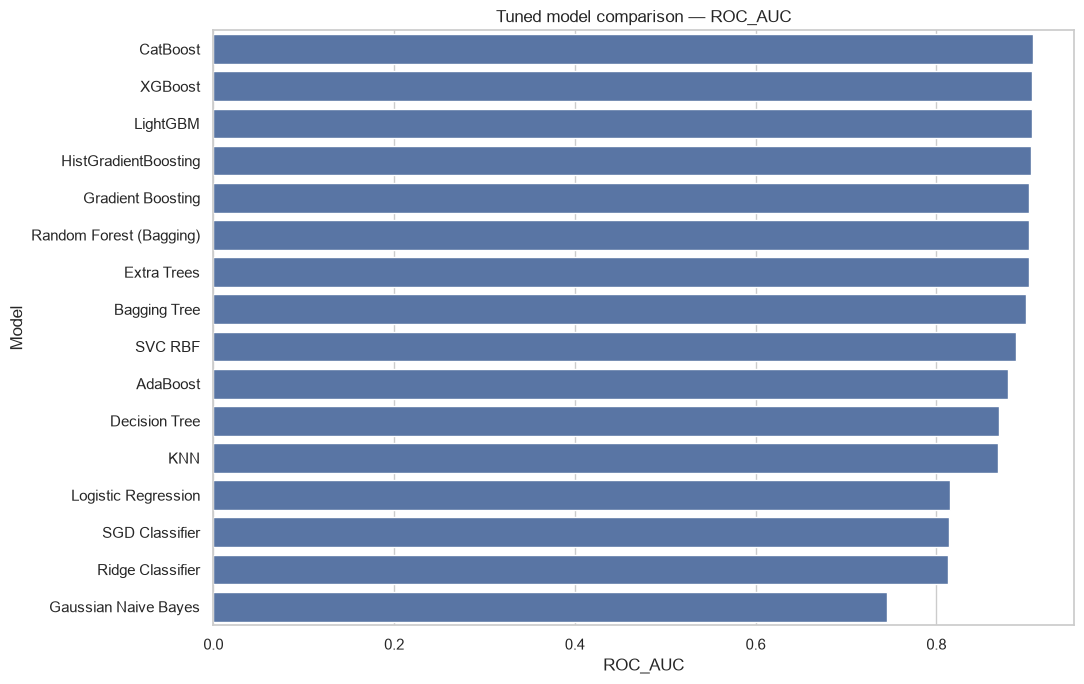

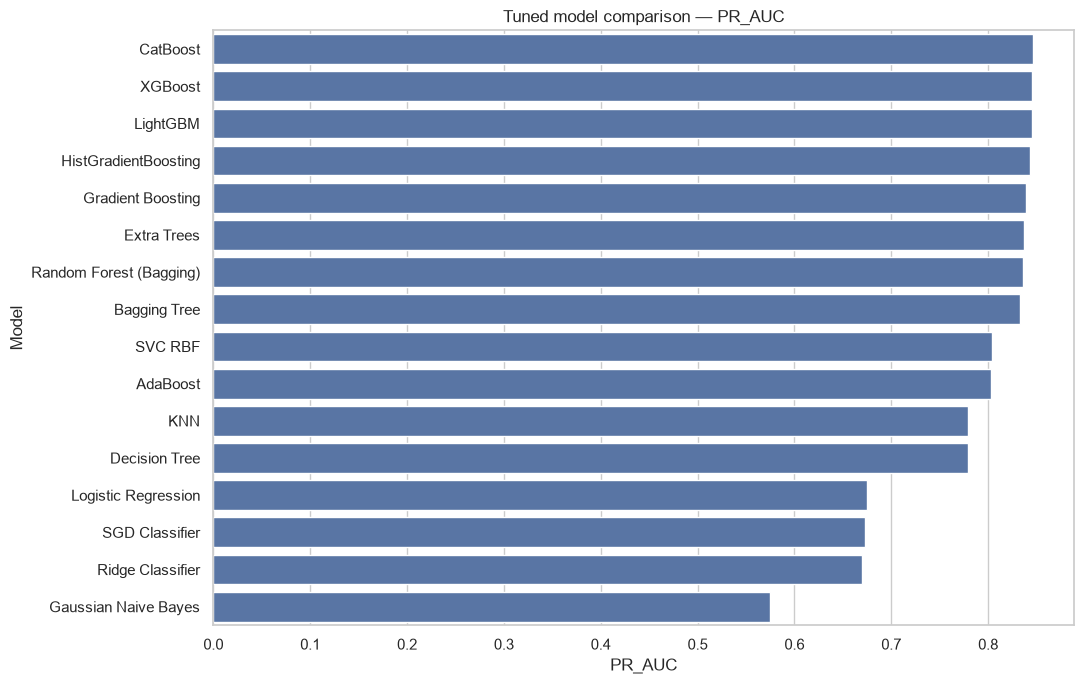

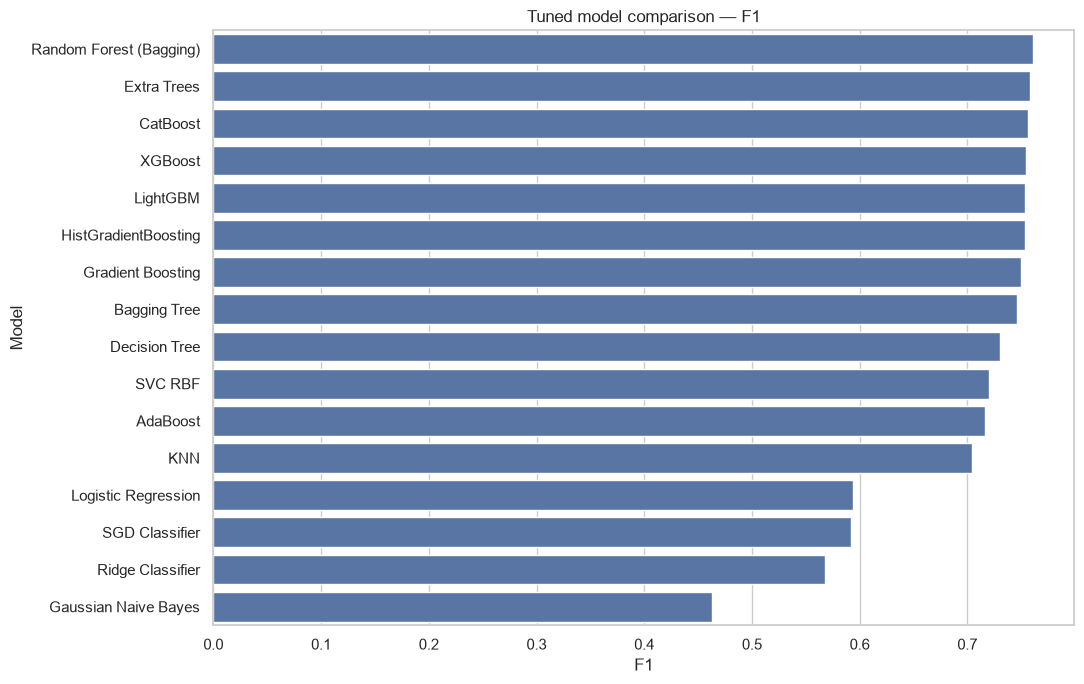

In [18]:
for metric in ["ROC_AUC","PR_AUC","F1"]:
    plt.figure(figsize=(11,7))
    sns.barplot(data=validation_results.sort_values(metric,ascending=False),x=metric,y="Model")
    plt.title(f"Tuned model comparison — {metric}")
    plt.tight_layout()
    plt.show()

## 14. Detailed evaluation of the best tuned model

Best model: CatBoost
                precision    recall  f1-score   support

Background (b)       0.86      0.90      0.88     32867
    Signal (s)       0.79      0.73      0.76     17133

      accuracy                           0.84     50000
     macro avg       0.83      0.81      0.82     50000
  weighted avg       0.84      0.84      0.84     50000



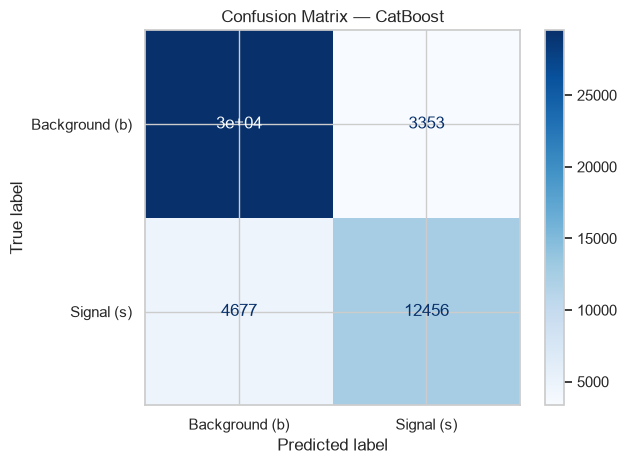

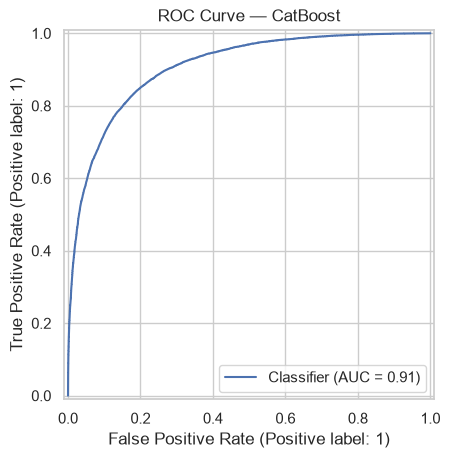

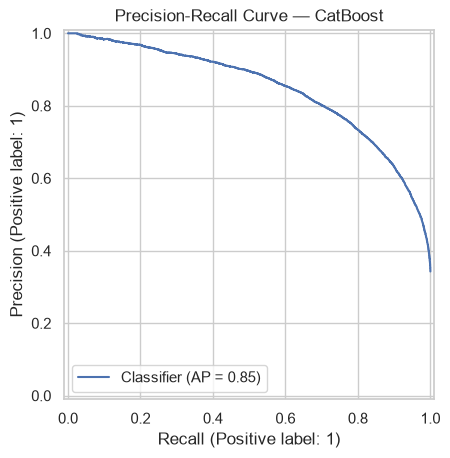

In [19]:
if validation_results.empty:
    raise RuntimeError("No model completed tuning successfully.")

best_model_name = validation_results.iloc[0]["Model"]
best_model = best_pipelines[best_model_name]
best_pred = best_model.predict(X_valid)
best_score = get_scores(best_model, X_valid)

print("Best model:", best_model_name)
print(classification_report(y_valid,best_pred,target_names=["Background (b)","Signal (s)"],zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_valid,best_pred,display_labels=["Background (b)","Signal (s)"],cmap="Blues"
)
plt.title("Confusion Matrix — "+best_model_name)
plt.tight_layout()
plt.show()

if best_score is not None:
    RocCurveDisplay.from_predictions(y_valid,best_score)
    plt.title("ROC Curve — "+best_model_name)
    plt.show()
    PrecisionRecallDisplay.from_predictions(y_valid,best_score)
    plt.title("Precision-Recall Curve — "+best_model_name)
    plt.show()

## 15. Optuna diagnostics

In [20]:
if best_model_name in studies:
    study = studies[best_model_name]
    try:
        optuna.visualization.plot_optimization_history(study).show()
        optuna.visualization.plot_param_importances(study).show()
    except Exception as e:
        print("Install plotly for Optuna charts: %pip install plotly")
        print(e)

## 16. Feature importance for tree-based models

,Feature,Importance
0,DER_mass_MMC,13.058984
1,DER_mass_transverse_met_lep,10.342220
2,DER_mass_vis,10.320200
13,PRI_tau_pt,6.944360
7,DER_deltar_tau_lep,6.892554
11,DER_met_phi_centrality,4.827584
24,PRI_jet_leading_eta,3.857004
17,PRI_lep_eta,3.641637
19,PRI_met,3.257202
14,PRI_tau_eta,3.160868


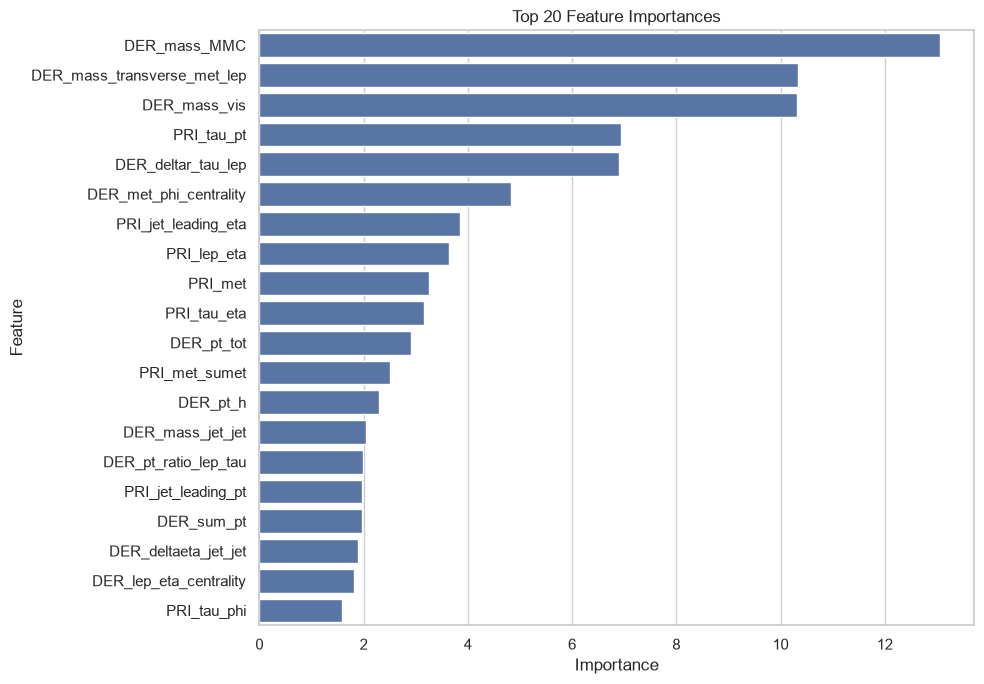

In [21]:
classifier = best_model.named_steps["classifier"]
if hasattr(classifier,"feature_importances_"):
    # Imputation indicators can increase the number of transformed columns.
    try:
        names = best_model.named_steps["preprocess"].get_feature_names_out(feature_columns)
        values = classifier.feature_importances_
        if len(names) == len(values):
            importance = pd.DataFrame({"Feature":names,"Importance":values}).sort_values("Importance",ascending=False)
            display(importance.head(20))
            plt.figure(figsize=(10,7))
            sns.barplot(data=importance.head(20),x="Importance",y="Feature")
            plt.title("Top 20 Feature Importances")
            plt.tight_layout()
            plt.show()
        else:
            print("Feature names and importance lengths differ.")
    except Exception as e:
        print("Could not extract feature names:",e)
else:
    print("This model has no native feature_importances_ attribute.")

## 17. Voting and Stacking ensembles
The top three tuned pipelines are used as base estimators. These ensembles may take additional time.

In [22]:
top_names = validation_results["Model"].head(3).tolist()
print("Top base models:",top_names)
ensemble_rows = []

if len(top_names) >= 2:
    top_estimators = [(f"base_{i}",best_pipelines[n]) for i,n in enumerate(top_names)]
    prob_estimators = [
        (n,e) for n,e in top_estimators
        if hasattr(e.named_steps["classifier"],"predict_proba")
    ]

    if len(prob_estimators) >= 2:
        voting = VotingClassifier(estimators=prob_estimators,voting="soft",n_jobs=1)
        voting.fit(X_train,y_train)
        vp = voting.predict(X_valid)
        vs = voting.predict_proba(X_valid)[:,1]
        ensemble_rows.append({
            "Model":"Soft Voting","Accuracy":accuracy_score(y_valid,vp),
            "F1":f1_score(y_valid,vp),"ROC_AUC":roc_auc_score(y_valid,vs),
            "PR_AUC":average_precision_score(y_valid,vs)
        })

    stacking = StackingClassifier(
        estimators=top_estimators,
        final_estimator=LogisticRegression(max_iter=2000),
        cv=3,stack_method="auto",n_jobs=1
    )
    stacking.fit(X_train,y_train)
    sp = stacking.predict(X_valid)
    ss = stacking.predict_proba(X_valid)[:,1]
    ensemble_rows.append({
        "Model":"Stacking","Accuracy":accuracy_score(y_valid,sp),
        "F1":f1_score(y_valid,sp),"ROC_AUC":roc_auc_score(y_valid,ss),
        "PR_AUC":average_precision_score(y_valid,ss)
    })

ensemble_results = pd.DataFrame(ensemble_rows)
display(ensemble_results)

Top base models: ['CatBoost', 'XGBoost', 'LightGBM']


,Model,Accuracy,F1,ROC_AUC,PR_AUC
0,Soft Voting,0.84202,0.759228,0.910106,0.851617
1,Stacking,0.84204,0.758456,0.910755,0.852707


## 18. Optional Higgs AMS metric
If `Weight` exists, calculate the competition-style Approximate Median Significance on validation data. Threshold selection must use validation data only.

In [23]:
def calculate_ams(y_true,y_pred,weights,regularization=10.0):
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred); weights=np.asarray(weights,dtype=float)
    s=weights[(y_true==1)&(y_pred==1)].sum()
    b=weights[(y_true==0)&(y_pred==1)].sum()
    if s<=0 or b<0: return 0.0
    value=2*((s+b+regularization)*np.log(1+s/(b+regularization))-s)
    return float(np.sqrt(max(value,0)))

if event_weights is not None and best_score is not None:
    w_valid=event_weights.loc[X_valid.index].to_numpy()
    ams=[]
    for threshold in np.linspace(0.1,0.9,17):
        pred=(best_score>=threshold).astype(int)
        ams.append({"Threshold":threshold,"AMS":calculate_ams(y_valid,pred,w_valid)})
    ams_results=pd.DataFrame(ams).sort_values("AMS",ascending=False)
    display(ams_results)
else:
    print("No event Weight column or probability/score unavailable — AMS skipped.")

,Threshold,AMS
13,0.75,1.519695
14,0.80,1.487298
12,0.70,1.481961
15,0.85,1.471843
11,0.65,1.417498
10,0.60,1.375374
16,0.90,1.317725
9,0.55,1.306878
8,0.50,1.278329
7,0.45,1.234664


## 19. Choose final model and refit using all labeled training data

In [24]:
# Default: highest validation ROC-AUC individual model.
# If an ensemble performs better, replace final_model with the fitted ensemble above.
final_model_name = best_model_name
final_model = best_pipelines[final_model_name]
if final_model_name == "SVC RBF":
    X_final, y_final = sample_for_model(final_model_name, X, y)
else:
    X_final, y_final = X, y
final_model.fit(X_final,y_final)
print("Final model:",final_model_name, "| rows used:", len(X_final))

Final model: CatBoost | rows used: 250000


## 20. Predict test data and save artifacts

In [25]:
test_pred = final_model.predict(X_test)
submission = pd.DataFrame({"Label":np.where(test_pred==1,"s","b")})
if hasattr(final_model,"predict_proba"):
    submission["Signal_Probability"] = final_model.predict_proba(X_test)[:,1]
if "EventId" in test_df.columns:
    submission.insert(0,"EventId",test_df["EventId"].values)

Path("results").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
submission.to_csv("results/higgs_test_predictions.csv",index=False)
joblib.dump(final_model,"models/higgs_best_pipeline.joblib")
baseline_results.to_csv("results/baseline_comparison.csv",index=False)
validation_results.to_csv("results/tuned_validation_comparison.csv",index=False)
tuning_results.to_json("results/optuna_results.json",orient="records",indent=2)

print("Saved predictions, model, and experiment results.")
display(submission.head())

Saved predictions, model, and experiment results.


,EventId,Label,Signal_Probability
0,350000,b,0.003861
1,350001,b,0.087043
2,350002,b,0.484488
3,350003,s,0.873303
4,350004,b,0.009276
